# B17 怎样用神经网络识别手写数字？

任务：把 8×8 手写数字转成分类结果，理解 Dataset、DataLoader 和批训练，并保存错误样例。

先修：B16 训练循环；补充 Dataset、批次、类别轴。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 读图像并划分样本
使用 sklearn 随包提供的真实 digits 小数据，不下载 MNIST。每张图 64 个灰度值除以 16；stratify 保持各数字比例。训练和测试的样本索引互不相交。

In [2]:
import json
import time
import numpy as np
started = time.perf_counter()
def finish(metrics):
    metrics["elapsed_seconds"] = round(time.perf_counter() - started, 3)
    (OUT_DIR / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2))
def barplot(labels, values, title, filename="comparison.png"):
    fig, ax = plt.subplots()
    ax.bar(labels, values)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(OUT_DIR / filename)
    plt.close(fig)

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
torch.set_num_threads(2)
torch.manual_seed(17)
digits = load_digits()
X = digits.data.astype('float32') / 16
y = digits.target
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, random_state=17, stratify=y)
assert not set(train_idx) & set(test_idx)
dataset = TensorDataset(torch.tensor(X[train_idx]), torch.tensor(y[train_idx], dtype=torch.long))
loader = DataLoader(dataset, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(17))
print('一个批次', next(iter(loader))[0].shape)

一个批次 torch.Size([64, 64])


## 2. 定义输出十个分数的分类器
最后一层输出 batch×10 logits，CrossEntropyLoss 会内部处理 log-softmax；目标是 long 类型类别编号，不是 one-hot。逻辑回归作为可解释的强基线。

In [3]:
baseline = LogisticRegression(max_iter=400).fit(X[train_idx], y[train_idx])
model = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.008)
assert model(torch.zeros(2, 64)).shape == (2, 10)

## 3. 批次训练与正确的平均损失
每个批次更新一次。累计 loss×样本数再除以总数，可避免最后一个短批次被赋予过大权重。固定 14 轮，测试集只在最后使用。

In [4]:
history = []
for epoch in range(14):
    model.train()
    total = 0.0
    for bx, by in loader:
        opt.zero_grad()
        loss = loss_fn(model(bx), by)
        loss.backward()
        opt.step()
        total += loss.item() * len(by)
    history.append(total / len(dataset))

## 4. 观察错分而不是只追准确率
argmax 沿类别轴取分数最高类别。混淆矩阵的行是真实数字、列是预测数字；错误列表用于后续找规律，不能据此反复改模型再声称独立测试。

In [5]:
model.eval()
with torch.no_grad():
    pred = model(torch.tensor(X[test_idx])).argmax(1).numpy()
base_pred = baseline.predict(X[test_idx])
cm = confusion_matrix(y[test_idx], pred)
errors = [{'sample': int(i), 'actual': int(a), 'predicted': int(p)} for i, a, p in zip(test_idx, y[test_idx], pred) if a != p]
(OUT_DIR / 'errors.json').write_text(json.dumps(errors, indent=2), encoding='utf-8')
fig, ax = plt.subplots()
im = ax.imshow(cm, cmap='Blues')
ax.set_xlabel('预测')
ax.set_ylabel('真实')
ax.set_title('数字混淆矩阵')
fig.colorbar(im, ax=ax)
fig.tight_layout()
fig.savefig(OUT_DIR / 'confusion.png')
plt.close(fig)
torch.save(model.state_dict(), OUT_DIR / 'digits_mlp.pt')
finish({'mlp_accuracy': float(accuracy_score(y[test_idx], pred)), 'logistic_accuracy': float(accuracy_score(y[test_idx], base_pred)), 'test_samples': len(test_idx), 'errors': len(errors)})

{
  "mlp_accuracy": 0.9688888888888889,
  "logistic_accuracy": 0.9711111111111111,
  "test_samples": 450,
  "errors": 14,
  "elapsed_seconds": 9.456
}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

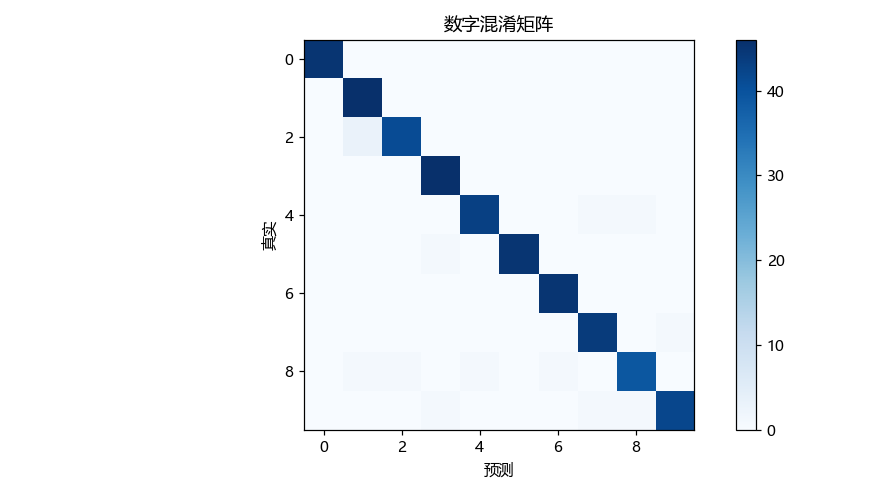

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
这里是 8×8 digits，不是 MNIST；不能直接移用论文中的 MNIST 成绩。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。